# Credit Card Default — Data Preparation and Model Training

This notebook documents the workflow. Run it from the project root after installing `requirements.txt`.
The reproducible end-to-end pipeline is implemented in `train_model.py`.

In [10]:
import sys
import subprocess

# Install pandas, numpy and matplotlib
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "pandas", "numpy", "matplotlib"
])

print("Libraries installed successfully!")

  Using cached pandas-3.1.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (16 kB)
  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.1-cp314-cp314-macosx_11_0_arm64.whl (11.3 MB)
Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl (5.5 MB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using 

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [12]:
df = pd.read_csv("../data/credit_card_default_clean.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (29965, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,default.payment.next.month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29965 entries, 0 to 29964
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   X1                          29965 non-null  int64
 1   X2                          29965 non-null  int64
 2   X3                          29965 non-null  int64
 3   X4                          29965 non-null  int64
 4   X5                          29965 non-null  int64
 5   X6                          29965 non-null  int64
 6   X7                          29965 non-null  int64
 7   X8                          29965 non-null  int64
 8   X9                          29965 non-null  int64
 9   X10                         29965 non-null  int64
 10  X11                         29965 non-null  int64
 11  X12                         29965 non-null  int64
 12  X13                         29965 non-null  int64
 13  X14                         29965 non-null  int64
 14  X15              

In [14]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,default.payment.next.month
count,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,...,29965.000000,29965.000000,29965.000000,29965.000000,2.996500e+04,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000
mean,167442.005006,1.603738,1.853629,1.551877,35.487969,-0.016753,-0.131854,-0.164392,-0.218922,-0.264509,...,43313.329885,40358.334390,38917.012281,5670.099316,5.927983e+03,5231.688837,4831.617454,4804.897047,5221.498014,0.221258
std,129760.135222,0.489128,0.790411,0.521997,9.219459,1.123492,1.196322,1.195878,1.168175,1.132220,...,64353.514373,60817.130623,59574.147742,16571.849467,2.305346e+04,17616.361124,15674.464538,15286.372298,17786.976864,0.415101
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2360.000000,1787.000000,1262.000000,1000.000000,8.500000e+02,390.000000,300.000000,261.000000,131.000000,0.000000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,19081.000000,18130.000000,17124.000000,2102.000000,2.010000e+03,1804.000000,1500.000000,1500.000000,1500.000000,0.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,54601.000000,50247.000000,49252.000000,5008.000000,5.000000e+03,4512.000000,4016.000000,4042.000000,4000.000000,0.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.000000,621000.000000,426529.000000,528666.000000,1.000000


In [15]:
target = "default.payment.next.month"

print(df[target].value_counts())

default.payment.next.month
0    23335
1     6630
Name: count, dtype: int64


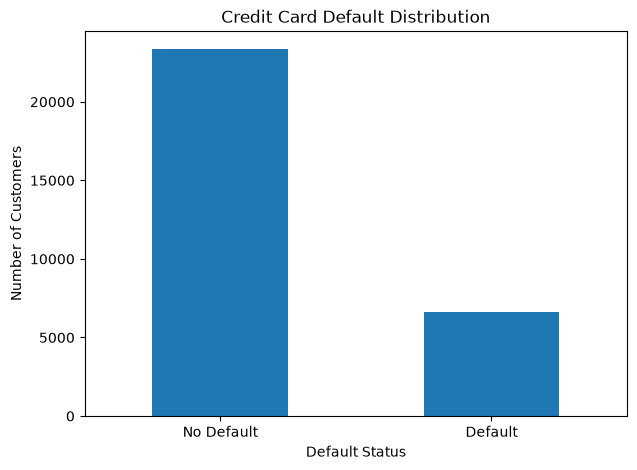

In [16]:
df[target].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No Default", "Default"], rotation=0)
plt.show()

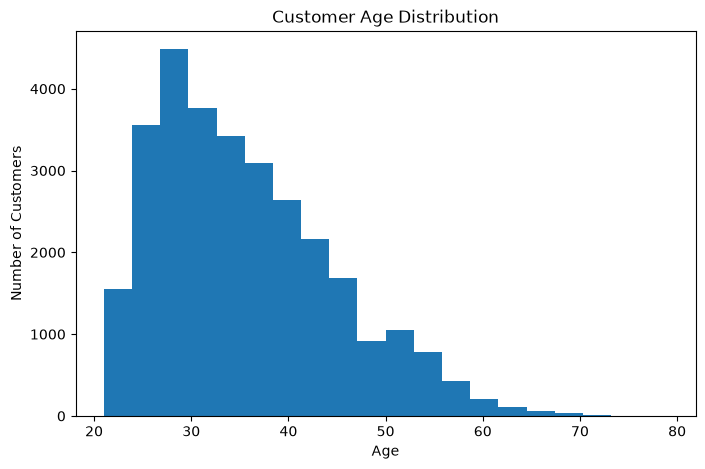

In [18]:
plt.figure(figsize=(8, 5))

# The cleaned data uses generic column names; X5 corresponds to age
plt.hist(df["X5"], bins=20)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
print("Average age:", df["X5"].mean())

Average age: 35.487969297513764


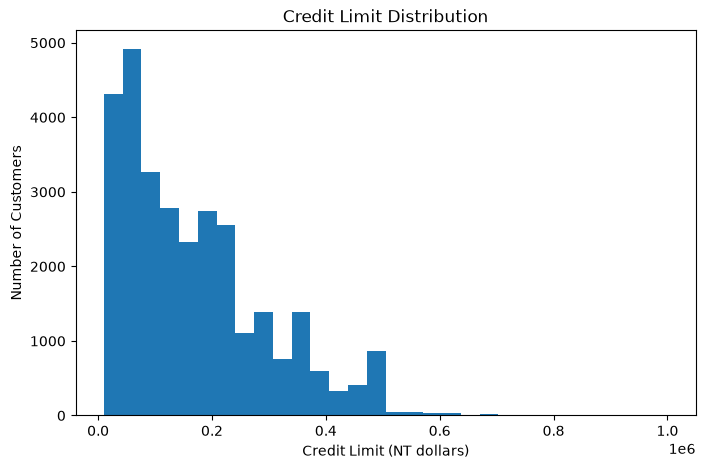

In [22]:
plt.figure(figsize=(8, 5))

# The cleaned data uses generic column names; X1 corresponds to credit limit
plt.hist(df["X1"], bins=30)

plt.title("Credit Limit Distribution")
plt.xlabel("Credit Limit (NT dollars)")
plt.ylabel("Number of Customers")

plt.show()

In [27]:
# The cleaned CSV uses generic column names; X1 is the credit limit
print(
    "Average credit limit:",
    df["X1"].mean()
)

Average credit limit: 167442.00500584015


In [29]:
print(df["X6"].value_counts().sort_index())

X6
-2     2750
-1     5682
 0    14737
 1     3667
 2     2666
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


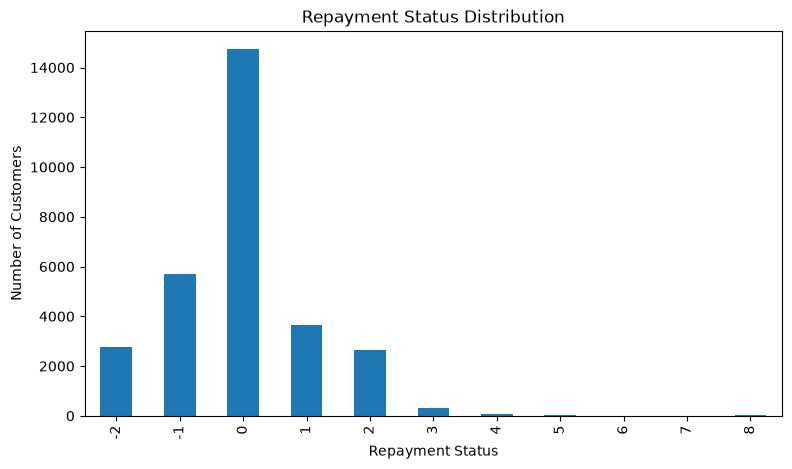

In [31]:
df["X6"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Repayment Status Distribution")
plt.xlabel("Repayment Status")
plt.ylabel("Number of Customers")

plt.show()

In [32]:
default_by_payment = df.groupby("X6")[
    "default.payment.next.month"
].mean() * 100

print(default_by_payment)

X6
-2    13.236364
-1    16.789863
 0    12.811291
 1    34.033270
 2    69.129782
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: default.payment.next.month, dtype: float64


In [34]:
default_by_payment = df.groupby("X6")[
    "default.payment.next.month"
].mean() * 100

print(default_by_payment)

X6
-2    13.236364
-1    16.789863
 0    12.811291
 1    34.033270
 2    69.129782
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: default.payment.next.month, dtype: float64


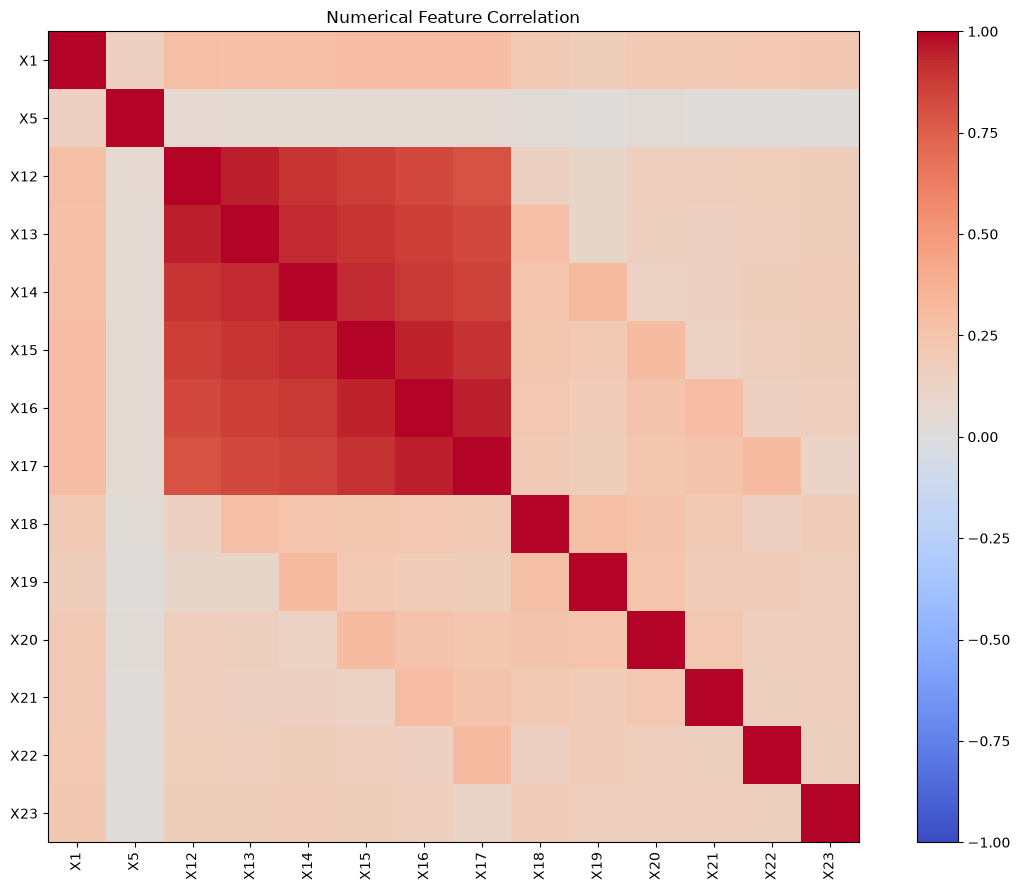

In [36]:
continuous_cols = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

# The cleaned CSV uses generic column names:
continuous_cols = [
    "X1", "X5",
    "X12", "X13", "X14", "X15", "X16", "X17",
    "X18", "X19", "X20", "X21", "X22", "X23"
]

correlation = df[continuous_cols].corr()

plt.figure(figsize=(12, 9))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(
    range(len(continuous_cols)),
    continuous_cols,
    rotation=90
)

plt.yticks(
    range(len(continuous_cols)),
    continuous_cols
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()
plt.show()

In [37]:
df.describe().to_csv(
    "../data/dataset_statistics.csv"
)

print("EDA statistics saved!")

EDA statistics saved!


In [38]:
# Define target column
target = "default.payment.next.month"

# Separate input features (X)
X = df.drop(columns=[target])

# Separate target (y)
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (29965, 23)
Target shape: (29965,)


In [39]:
categorical_features = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

Numerical features:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']


In [41]:
import sys
import subprocess

# Install scikit-learn if it is missing in this notebook environment
subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Training data: (23972, 23)
Testing data: (5993, 23)


In [43]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

# The cleaned dataset uses generic column names, not the original raw names.
categorical_features = ["X2", "X3", "X4", "X6", "X7", "X8", "X9", "X10", "X11"]

encoded_data = encoder.fit_transform(
    X_train[categorical_features]
)

print("Encoded data shape:", encoded_data.shape)

Encoded data shape: (23972, 76)


In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    X_train[numerical_features]
)

print("Scaled data shape:", scaled_data.shape)

Scaled data shape: (23972, 23)


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [47]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [46]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [48]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])